# 🧪 LAB: Implement an autoencoder with `PyTorch`

In this lab, you will implement and explore autoencoders using the MNIST dataset. The goal is to understand how autoencoders learn compressed representations of data, and how these representations compare with classical methods like PCA.

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Anh Phan, Braden Cruz, Emerson Brown"

## 1. Theoretical Background Reflection (10 points)

Read *Michelucci (2022)*: [An Introduction to Autoencoders](https://arxiv.org/abs/2201.03898) — focus on the following sections:  
- 1. Introduction
- 2.1, 2.2, and 2.3
- Skim Section 3 on applications  

Then answer briefly:

1. What is the main idea behind an autoencoder?  
- An autoencoder is a type of neural network that compresses data into a smaller representation and then reconstructs the original data from that. It tries to learn the most important features and patterns of the data while minimizing the differences between the reconstructed input and original input.

2. What is the role of the bottleneck layer?  
- The bottleneck layer is the compressed representation of the input data. It is the layer that learns the most important features of the input data since it normally has fewer dimensions than the original. 
  
3. Discuss, in your own words, the applications of autoencoders mentioned in the paper.  
- The paper demonstrates autoencoders on image data, using MNIST handwritten digits and Fashion-MNIST (clothing and shoes), to show how images can be compressed and reconstructed. It then discusses four typical applications: dimensionality reduction (the bottleneck gives a compact representation of the data), classification (the learned features can feed a classifier), denoising (recovering a clean image from a corrupted one), and anomaly detection (inputs that reconstruct poorly are likely unlike the training data).
  
4. What differences would you expect between an autoencoder’s representation and that of PCA if applied as a dimensionality reduction technique?
- Autoencoders can capture nonlinear relationships while PCA can only record linear relationships. This comes in handy when there are complex patterns that PCA could miss, but, on the other hand, PCA is very good at finding the directions of greatest variance and projecting onto them. PCA is fast and lighter while autoencoders take a lot of time, data, and resources to train. 


## 2. Prepare the Data (10 points)

Given the below dataset:

- Normalize **each** image (i.e., separately) so its values are between 0 and 1. Remember our first-week discussions of fixed and fitted transformations.
- Visualize a few random digits to confirm everything worked as expected.
- Split the dataset into fitting, tuning and reporting sets (70%, 15%, 15%).
- Wrap each data splitting as `DataLoader` object with a batch size of 128. Call them `fitting_loader`, `tuning_loader` and `reporting_loader`, respectively.

In [20]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784", version=1, as_frame=False, parser="liac-arff", n_retries=5, delay=2)
X, y = mnist.data, mnist.target.astype(int)

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split

SEED = 42
BATCH_SIZE = 128
np.random.seed(SEED)
torch.manual_seed(SEED)

**Normalization.** We scale each image by its own minimum and maximum: $x' = (x - \min(x)) / (\max(x) - \min(x))$.
This is a **fixed** transformation. It uses only the values of one image, and it learns no parameters from the dataset.
Because of this, we can apply it before the split without data leakage. A fitted transformation (for example, `MinMaxScaler` on each pixel column) must be fit on the fitting set only.

In [22]:
X_min = X.min(axis=1, keepdims=True)
X_max = X.max(axis=1, keepdims=True)
X_norm = ((X - X_min) / (X_max - X_min)).astype(np.float32)

print(f"Shape: {X_norm.shape}")
print(f"Global min: {X_norm.min():.2f}, global max: {X_norm.max():.2f}")
print(f"Every image spans [0, 1]: {np.allclose(X_norm.min(axis=1), 0) and np.allclose(X_norm.max(axis=1), 1)}")

Shape: (70000, 784)
Global min: 0.00, global max: 1.00
Every image spans [0, 1]: True


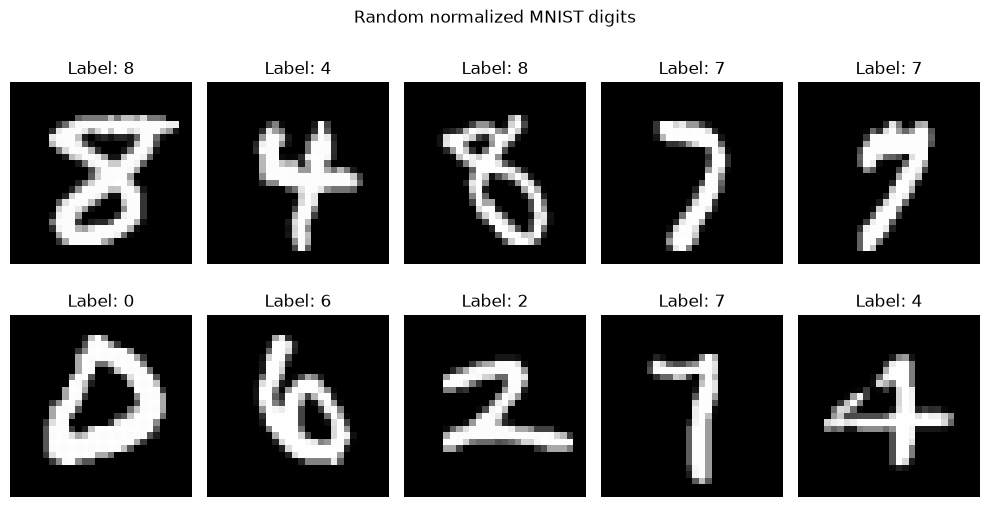

In [23]:
idx = np.random.choice(len(X_norm), size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(10, 5.5))
for ax, i in zip(axes.flat, idx):
    ax.imshow(X_norm[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {y[i]}")
    ax.axis("off")
plt.suptitle("Random normalized MNIST digits")
plt.tight_layout()
plt.show()

**Split.** We first separate 70% for fitting. Then we split the remaining 30% in half for tuning and reporting (15% each).
We stratify by label, so each set has the same digit proportions.

In [24]:
X_fitting, X_rest, y_fitting, y_rest = train_test_split(
    X_norm, y, test_size=0.30, stratify=y, random_state=SEED
)
X_tuning, X_reporting, y_tuning, y_reporting = train_test_split(
    X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=SEED
)

for name, part in [("Fitting", X_fitting), ("Tuning", X_tuning), ("Reporting", X_reporting)]:
    print(f"{name:<10} {part.shape[0]:>6} samples ({part.shape[0] / len(X_norm):.0%})")

Fitting     49000 samples (70%)
Tuning      10500 samples (15%)
Reporting   10500 samples (15%)


**DataLoaders.** Each dataset holds `(image, label)` pairs. The autoencoder uses only the image, but we keep the label for the latent-space plots in Section 4.
Only the fitting loader shuffles. The tuning and reporting loaders keep a fixed order, so the reconstructions and latent features align with `X_reporting` and `y_reporting`.

In [25]:
def make_loader(X_part, y_part, shuffle):
    dataset = TensorDataset(torch.tensor(X_part), torch.tensor(y_part))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle)

fitting_loader = make_loader(X_fitting, y_fitting, shuffle=True)
tuning_loader = make_loader(X_tuning, y_tuning, shuffle=False)
reporting_loader = make_loader(X_reporting, y_reporting, shuffle=False)

X_batch, y_batch = next(iter(fitting_loader))
print(f"Batch X: {tuple(X_batch.shape)} {X_batch.dtype}, batch y: {tuple(y_batch.shape)} {y_batch.dtype}")
print(f"Batches -> fitting: {len(fitting_loader)}, tuning: {len(tuning_loader)}, reporting: {len(reporting_loader)}")

Batch X: (128, 784) torch.float32, batch y: (128,) torch.int64
Batches -> fitting: 383, tuning: 83, reporting: 83


## 3. Autoencoder

In this section, you will build and train an **autoencoder** to reconstruct the provided data.

Your model will include three layers in both the encoder and decoder:

- **Encoder:** 784 → 128 → 64 → 2. This last layer here is the **bottleneck**.
- **Decoder:** 2 → 64 → 128 → 784  

### 3.1 Implementation (30 points)

Follow the skeleton provided below and fill in the missing parts (`#TODO`). 

Follow these restrictions:

- Each **hidden** layer should include a linear transformation, ReLU activation function, dropout with `p=0.2` and batch normalization steps. Determine the appropriate order for these components based on what we discussed in class. The bottleneck layer is the exception; see next point.
- For the bottleneck, use only a linear transformation, i.e., no activation, batch normalization, or dropout.
- The output layer should have a sigmoid activation function.

In [27]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        
        # ENCODING PART: 784 -> 128 -> 64 -> 2
        encoder_list = [
            # 784 to 128 
            nn.Linear(784, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            # 128 to 64 
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            # 64 to 2 
            nn.Linear(64, 2)
        ]
        # stores the layers in 'encoder_list' for manual iteration in the forward pass
        self.encoder_list = nn.ModuleList(encoder_list)
        
        # DECODING PART: 2 -> 64 -> 128 -> 784
        decoder_list = [
            # 2 to 64
            nn.Linear(2, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            # 64 to 128
            nn.Linear(64, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            # 128 to 784
            nn.Linear(128, 784),
            nn.Sigmoid()
        ]
        # stores the layers in 'decoder_list' for manual iteration in the forward pass
        self.decoder_list = nn.ModuleList(decoder_list)

    def forward(self, X):
        output = X
        for layer in self.encoder_list:
            output = layer(output)
        for layer in self.decoder_list:
            output = layer(output)
        return output


### 3.2 Training (15 points)

Follow the skeleton provided below and fill in the missing parts to train your model (`#TODO`). As you can see, training includes EarlyStopping, which I give you already for your convenience :-). After you have filled these missing parts, uncomment the provided piece of code with the function for training (`train_autoencoder`) your model and execute it.

But, **BEFORE** that, discuss with your mates and provide elaborated answers to the following:

- Why do you think the output layer of the autoencoder above uses a Sigmoid activation?
- Based on this, which cost function is most appropriate for this task? Justify your choice.

1. Every pixel in our normalized image lies in [0,1]. Sigmoid squashes any real number into (0,1) so the decoder can only produce values in the same range as the data. Without it, the final linear layer could output values below 0 or above 1, which are not valid pixel intensities. 
2. We would use Binary cross-entropy. The outputs are in (0, 1) and the targets are in [0, 1], so each pixel can be treated as a probability or intensity that the model should match. Binary cross-entropy pairs with a sigmoid output, because its gradients stay well behaved when the sigmoid saturates. Although MSE would also work and is common for continuous reconstruction, binary cross entropy penalizes confident wrong pixels more heavily. That is useful on MNIST, where most pixels are near 0 or near 1.

Once you have discussed and agreed on the reasoning above, proceed to complete the skeleton (`#TODO`) and train the model.


In [ ]:
# instantiate the autoencoder
model = Autoencoder()

# pixel values and the output of the decoder are in [0,1], so we use Binary Cross Entropy loss
criterion = nn.BCELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

In [29]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, tuning_loss, model):
        if self.best_loss is None or tuning_loss < self.best_loss - self.min_delta:
            self.best_loss = tuning_loss
            self.counter = 0
            self.best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)


def train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=100, patience=5):
    # Initialize the early stopping object
    early_stopping = EarlyStopping(patience=patience)
    history = {"fitting": [], "tuning": []}

    for epoch in range(n_epochs):
        model.train()
        fitting_cost = 0.0

        for X_batch, _ in fitting_loader:
            # --- Implement the standard training steps ---
            
            outputs = model(X_batch)  # Forward pass for this batch
            cost = criterion(outputs, X_batch)  # Compute the cost for this batch
            # Backward pass (compute gradients)
            cost.backward()
            # Update model parameters
            optimizer.step()
            # Set gradients equal to zero
            optimizer.zero_grad()
            fitting_cost += cost.item() * X_batch.size(0)

        fitting_cost /= len(fitting_loader.dataset)

        # --- Tuning phase ---
        model.eval()
        tuning_cost = 0.0
        with torch.no_grad():
            for X_batch, _ in tuning_loader:
                outputs = model(X_batch)  # Forward pass for tuning data
                cost = criterion(outputs, X_batch)  # Compute the tuning cost
                tuning_cost += cost.item() * X_batch.size(0)

        tuning_cost /= len(tuning_loader.dataset)

        # --- Save metrics ---
        history["fitting"].append(fitting_cost)
        history["tuning"].append(tuning_cost)

        print(f"Epoch [{epoch+1}/{n_epochs}]  Fitting Cost: {fitting_cost:.5f}  Tuning Cost: {tuning_cost:.5f}")

        # --- Early stopping check ---
        early_stopping(tuning_cost, model)
        if early_stopping.early_stop:
            print(f"Stopping early at epoch {epoch+1}")
            early_stopping.restore_best_weights(model)
            return model, history

    return model, history


Once the missing parts have been filled, uncomment the piece of code below and execute it to train your model (it may take a bit to complete the training, which is totally normal).

In [30]:
model, history = train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=50, patience=5)

Epoch [1/50]  Fitting Cost: 0.25863  Tuning Cost: 0.21131
Epoch [2/50]  Fitting Cost: 0.21338  Tuning Cost: 0.20416
Epoch [3/50]  Fitting Cost: 0.20925  Tuning Cost: 0.20055
Epoch [4/50]  Fitting Cost: 0.20710  Tuning Cost: 0.19869
Epoch [5/50]  Fitting Cost: 0.20585  Tuning Cost: 0.19737
Epoch [6/50]  Fitting Cost: 0.20495  Tuning Cost: 0.19655
Epoch [7/50]  Fitting Cost: 0.20428  Tuning Cost: 0.19616
Epoch [8/50]  Fitting Cost: 0.20369  Tuning Cost: 0.19535
Epoch [9/50]  Fitting Cost: 0.20334  Tuning Cost: 0.19519
Epoch [10/50]  Fitting Cost: 0.20267  Tuning Cost: 0.19405
Epoch [11/50]  Fitting Cost: 0.20249  Tuning Cost: 0.19374
Epoch [12/50]  Fitting Cost: 0.20223  Tuning Cost: 0.19347
Epoch [13/50]  Fitting Cost: 0.20206  Tuning Cost: 0.19328
Epoch [14/50]  Fitting Cost: 0.20172  Tuning Cost: 0.19306
Epoch [15/50]  Fitting Cost: 0.20160  Tuning Cost: 0.19270
Epoch [16/50]  Fitting Cost: 0.20126  Tuning Cost: 0.19229
Epoch [17/50]  Fitting Cost: 0.20113  Tuning Cost: 0.19238
Epoch 

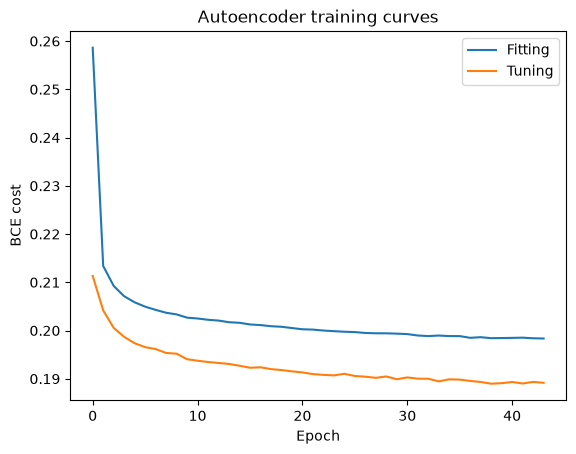

In [31]:
plt.plot(history["fitting"], label="Fitting")
plt.plot(history["tuning"], label="Tuning")
plt.xlabel("Epoch"); plt.ylabel("BCE cost"); plt.legend()
plt.title("Autoencoder training curves")
plt.show()

### 3.3 Reconstruct (5 points)

Once you have trained the model: 

1. Visualize several reconstructed digits from the reporting set.  
2. Compare them with the corresponding original input digits. Was the reconstruction good? 

Reporting cost: 0.18891


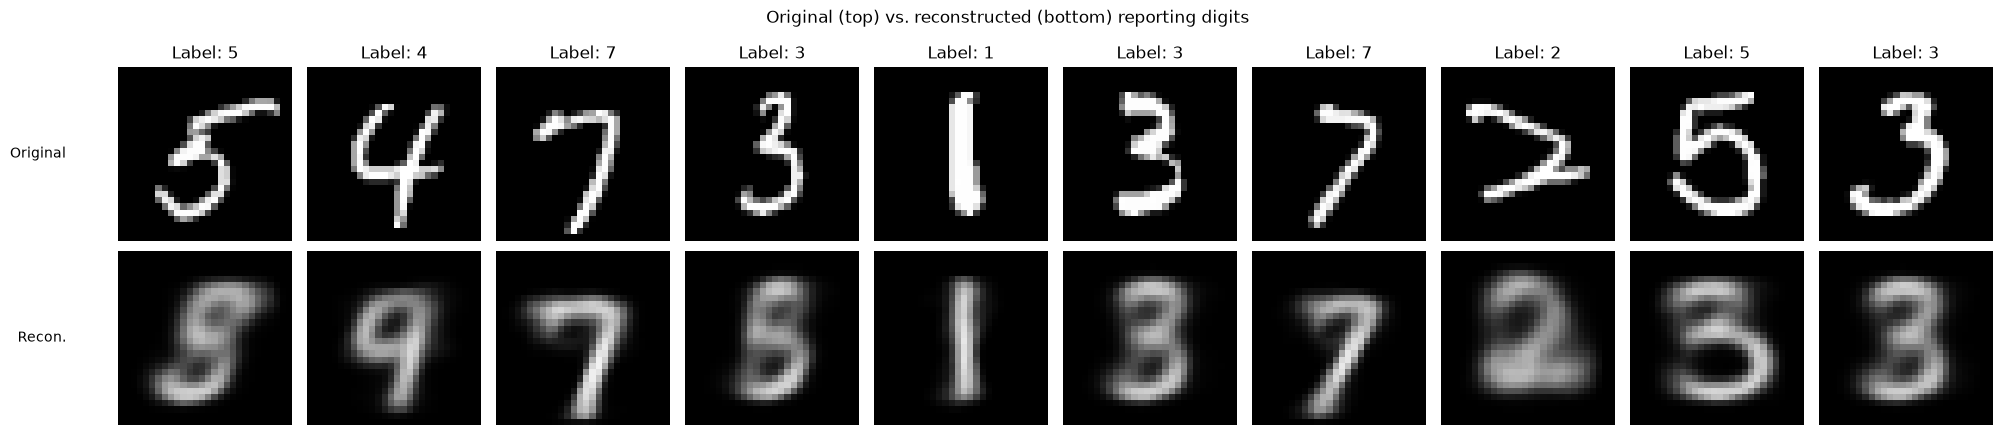

In [32]:
model.eval()
X_rep = torch.tensor(X_reporting)

with torch.no_grad():
    recon = model(X_rep)
    rep_cost = criterion(recon, X_rep).item()
print(f"Reporting cost: {rep_cost:.5f}")

n = 10
idx = np.random.choice(len(X_rep), size=n, replace=False)

fig, axes = plt.subplots(2, n, figsize=(2 * n, 4.5))
for j, i in enumerate(idx):
    axes[0, j].imshow(X_rep[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axes[0, j].set_title(f"Label: {y_reporting[i]}")
    axes[0, j].axis("off")
    axes[1, j].imshow(recon[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axes[1, j].axis("off")
axes[0, 0].text(-0.3, 0.5, "Original", transform=axes[0, 0].transAxes, ha="right", va="center")
axes[1, 0].text(-0.3, 0.5, "Recon.", transform=axes[1, 0].transAxes, ha="right", va="center")
plt.suptitle("Original (top) vs. reconstructed (bottom) reporting digits")
plt.tight_layout()
plt.show()

The reconstruction was okay. It captured the general shape and slant of most digits, and simple digits like 1 and 7 are reproduced well. However, they are noticeably blurrier than the originals, and fine details are lost. Several digits are reconstructed as a different, visually similar class: the 4 became a 9, and some 3s and 5s look like each other or like an 8. This is expected, since the bottleneck compresses 784 pixels into just 2 numbers, so the decoder can only recover an “average looking” digit near that point in latent space. The reporting cost (0.189) is close to the tuning cost, so the model generalizes well, and the limitation comes from the 2-dimensional bottleneck, not from overfitting. A larger bottleneck would give sharper reconstructions, at the cost of a latent space.

## 4. Visualize the Learned Representations (15 points)

Here you will explore the latent representations learned by your autoencoder.

1. Complete `extract_latent_features` to extract the latent (bottleneck) features and their corresponding labels, given a trained model.  
   Apply this function to the reporting set using the provided code. This should give you the transformed reporting set with the dimensions of the bottleneck (2).
2. Plot the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.


In [ ]:
def extract_latent_features(model, dataloader): 
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            
            encoded = None  # TODO: Apply the encoder part of the model to get the latent features
            latents.append(encoded.numpy())
            labels.append(y_batch.numpy())

    # Concatenate all batches
    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)
    return latents, labels

Once the missing parts above have been filled, uncomment the piece of code below and execute it to extract the latent features

In [ ]:
# latents_autoencoder, labels = extract_latent_features(model, reporting_loader)

In [ ]:
# USE AS MANY CELLS AS NEEDED FOR THE REST OF THE CODE

## 5. Compare with PCA (10 points)

Here you will compare the latent representations learned by your autoencoder with those obtained using a PCA.

1. Apply a PCA to the reporting set (without using the autoencoder) to reduce the data to the same dimensionality as your bottleneck (2 dimensions). Obviously, first use the rest of the data to learn these two components.
2. Visualize the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.
3. Compare the structure of the two plots (Autoencoder vs. PCA) and briefly discuss the differences (if any) you observe.

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE